In [2]:
import importlib
importlib.reload(importlib.import_module('RelaxationMover_RFM'))
from RelaxationMover_RFM import *

device = "cuda:3" if torch.cuda.is_available() else "cpu"
print(device)
torch.set_default_device(device)
torch.set_default_dtype(torch.float64)
if device == "cpu":
    torch.set_num_threads(4)

seed = 42
torch.cuda.empty_cache()
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
rand_gen = torch.Generator(device=device)
rand_gen.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

import numpy as np
np.random.seed(seed)

cuda:3


In [3]:
def unit_square_mesh(steps = 50, quad=True):
    x = torch.linspace(0, 1, steps + 1)
    y = torch.linspace(0, 1, steps + 1)
    x = x.repeat(steps + 1)
    y = y.repeat_interleave(steps + 1)
    V = torch.stack([x, y], dim=1)

    T = []
    if quad == False:
        for i in range(steps):
            for j in range(steps):
                T.append([j * (steps + 1) + i, j * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i + 1])
                T.append([j * (steps + 1) + i, (j + 1) * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i])
    else:
        for i in range(steps):
            for j in range(steps):
                T.append([j * (steps + 1) + i, j * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i + 1, (j + 1) * (steps + 1) + i])
    T = torch.tensor(T, dtype=torch.long)

    return V, T

In [4]:
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import matplotlib.gridspec as gridspec

def draw_quad_mesh(V, T, ax=None, linewidth=0.3):
    if ax is None:
        _, ax = plt.subplots()
    verts = V[T].cpu().numpy()
    polyc = PolyCollection(verts, edgecolors='k', linewidths=linewidth, facecolors='none')
    ax.add_collection(polyc)
    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')

Decomposing the problem size of A:  torch.Size([11401, 1000]) with solver QR
Offline time: 0.73 seconds
Stopped (relative_move_rate), best CV: (83, 3.51548734e-03), best relative move rate: (83, 8.22659379e-09), run time: 2.24s
Stopped (relative_move_rate), best CV: (63, 2.36285877e-03), best relative move rate: (85, 9.39894718e-09), run time: 2.23s
Stopped (relative_move_rate), best CV: (82, 4.58365273e-03), best relative move rate: (83, 9.32241462e-09), run time: 2.14s
Stopped (relative_move_rate), best CV: (83, 3.51548734e-03), best relative move rate: (83, 8.24108437e-09), run time: 2.14s


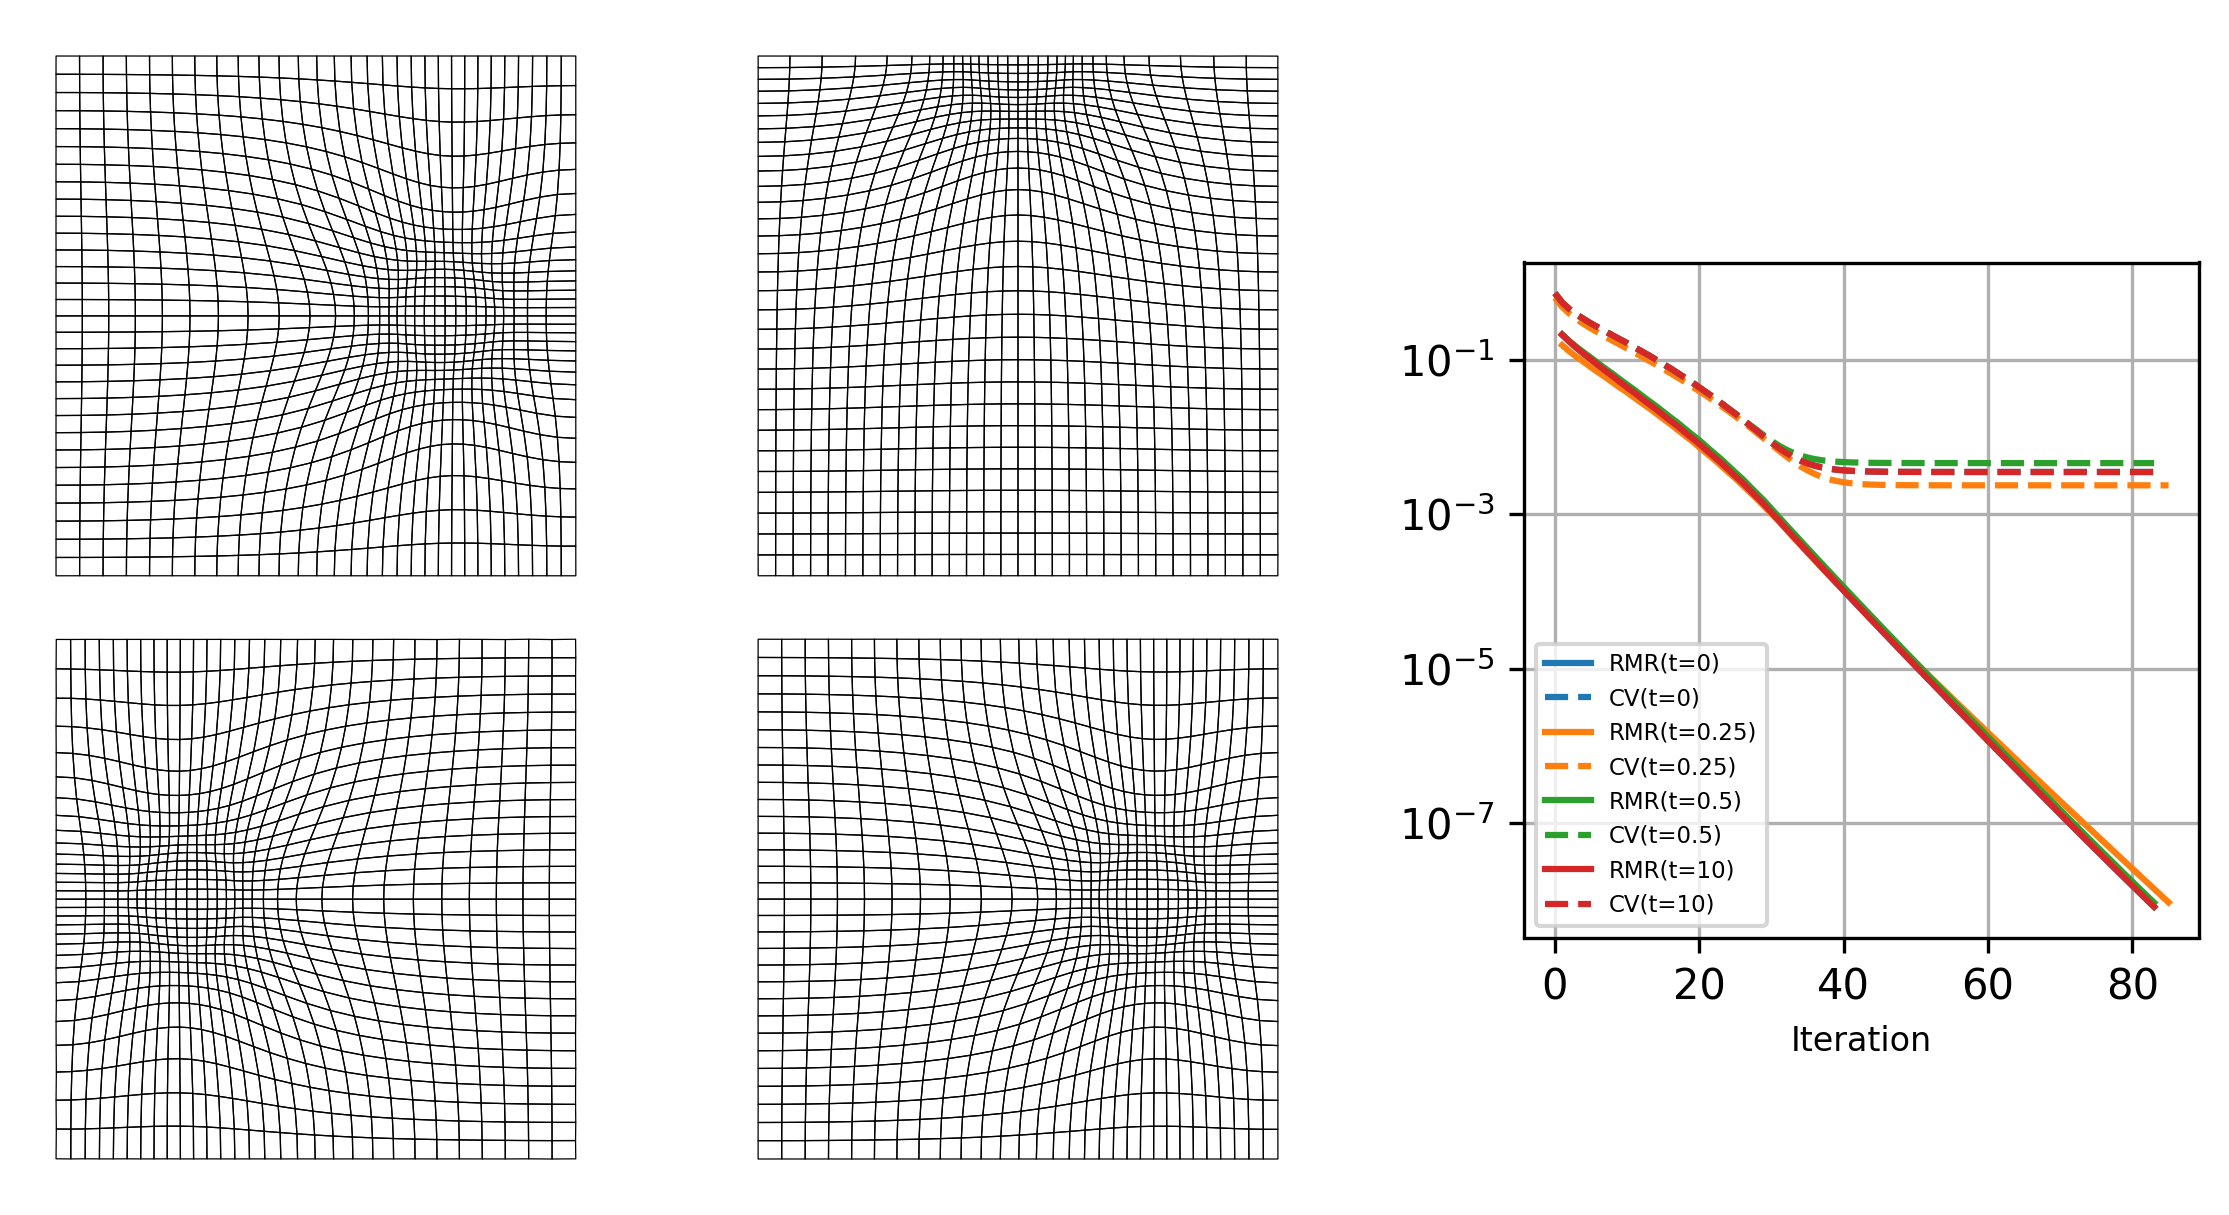

In [5]:
def monitor(t=0.0):
    t = torch.as_tensor(t)
    def monitor_(X):
        return 1 + 5*torch.exp(-50 * torch.abs((X[:, 0] - 0.5 - 0.25 * torch.cos(2*torch.pi*t))**2 + 
                                            (X[:, 1] - 0.5 - 0.5 * torch.sin(2*torch.pi*t))**2 - 0.01))
    return monitor_

t_list = [0, 0.25, 0.5, 10]

domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])
V, T = unit_square_mesh(30, quad=True)
rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400, corner1=torch.tensor([[0.0, 0.0]], device=device),
                    n_hidden=1000,  n_subdomains=1, pou='PsiA', rf='tanh3', damp_value=1e-8)
it_cfg = IterationConfig(maxiter=600, rtol=1e-8, pseudo_dt=0.1, early_stop_num=5, verbose=False)

mover = RelaxationMover_RFM(domain, rfm_cfg)
print(f'Offline time: {mover.build_time:.2f} seconds')

residual_CV_list_circles = []
relative_move_rate_list_circles = []

fig = plt.figure(figsize=(9, 5), dpi=300)
gs = gridspec.GridSpec(2, 3, width_ratios=[1, 1, 1], wspace=0.02, hspace=0.02)
positions = [(0, 0), (0, 1), (1, 0), (1, 1)]
for i, t in enumerate(t_list):
    row, col = positions[i]
    ax = fig.add_subplot(gs[row, col])

    monitor_func = monitor(torch.tensor(t))
    mover.relaxation(monitor_func, it_cfg)
    #print(f'Online time (t={t}): {mover.run_time:.2f} seconds, CV:{mover.best_CV_residual:.2e}')
    adapt_V = mover.move(V)
    draw_quad_mesh(adapt_V, T, ax=ax)

    residual_CV_list_circles.append(mover.CV_residual_record)
    relative_move_rate_list_circles.append(mover.relative_move_rate_record)

ax2 = fig.add_subplot(gs[:, 2])
ax2.set_position([0.70, 0.15, 0.25, 0.7])
for i, residual_CV in enumerate(residual_CV_list_circles):
    line, = ax2.semilogy(relative_move_rate_list_circles[i], label=f'RMR(t={t_list[i]})')
    ax2.semilogy(residual_CV, '--', color=line.get_color(), label=f'CV(t={t_list[i]})')
ax2.set_xlabel("Iteration", fontsize=8)
ax2.grid(True)
ax2.set_box_aspect(1)
ax2.legend(fontsize=5.5)
plt.savefig('circles.pdf', bbox_inches='tight', dpi=300)
plt.show()
plt.close()

del mover

Decomposing the problem size of A:  torch.Size([11401, 1000]) with solver QR
Stopped (relative_move_rate), best CV: (162, 1.42102665e-01), best relative move rate: (162, 9.51322457e-09), run time: 4.04s
Offline time: 0.50 seconds, Online time: 4.04 seconds
CV residual: 1.42e-01


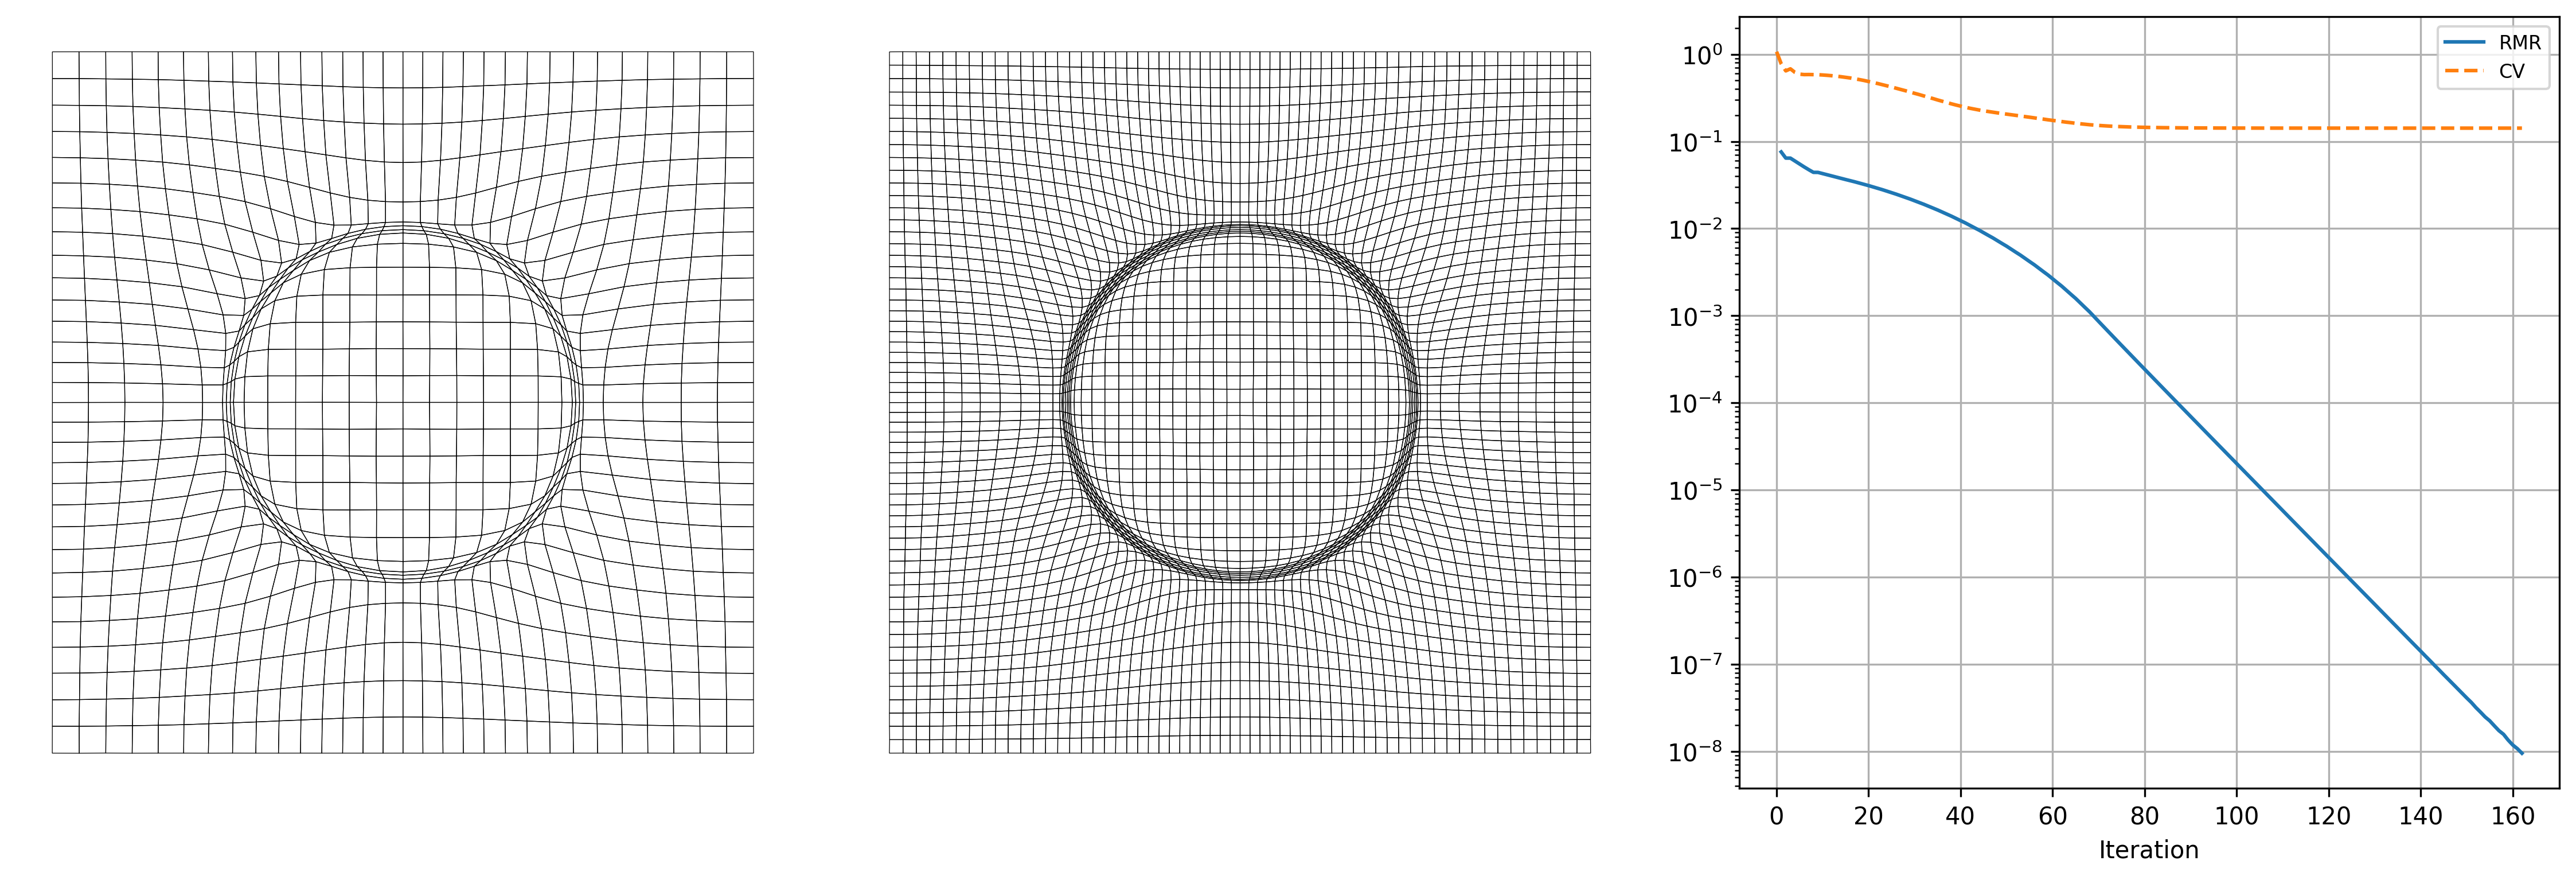

In [ ]:
def monitor_ring(X):
    a = 0.25
    alpha1 = 10
    alpha2 = 200
    r2 = (X[:, 0] - 0.5)**2 + (X[:, 1] - 0.5)**2
    return 1.0 + alpha1 / (torch.cosh(alpha2 * (r2 - a*a)) ** 2)
    
domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])
rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400, corner1=torch.tensor([[0.0, 0.0]], device=device), boundary_lambda=100,
                    n_hidden=1000, gamma=2.0, n_subdomains=1, pou='PsiA', rf='tanh3', damp_value=1e-8)

it_cfg = IterationConfig(maxiter=600, rtol=1e-8, pseudo_dt=0.1, early_stop_num=10, verbose=False)

mover = RelaxationMover_RFM(domain, rfm_cfg)
mover.relaxation(monitor_ring, it_cfg)
print(f'Offline time: {mover.build_time:.2f} seconds, Online time: {mover.run_time:.2f} seconds')
print(f'CV residual: {mover.best_CV_residual:.2e}')

fig, ax = plt.subplots(1, 3, figsize=(15, 5), dpi=300, layout='constrained')

V1, T1 = unit_square_mesh(30, quad=True)
adapt_V = mover.move(V1)
draw_quad_mesh(adapt_V, T1, ax=ax[0])

V2, T2 = unit_square_mesh(60, quad=True)
adapt_V = mover.move(V2)
draw_quad_mesh(adapt_V, T2, ax=ax[1])

ax[2].semilogy(mover.relative_move_rate_record, label="RMR")
ax[2].semilogy(mover.CV_residual_record, "--", label="CV")
ax[2].legend(fontsize=8)
ax[2].set_xlabel("Iteration")
ax[2].grid(True)


plt.savefig('ring.pdf', bbox_inches='tight')
plt.show()
plt.close()

del mover

Decomposing the problem size of A:  torch.Size([11901, 1500]) with solver QR
Stopped (relative_move_rate), best CV: (108, 1.70244120e-01), best relative move rate: (272, 8.07669333e-09), run time: 9.78s
Offline time: 0.71 seconds, Online time: 9.78 seconds
CV residual: 1.70e-01


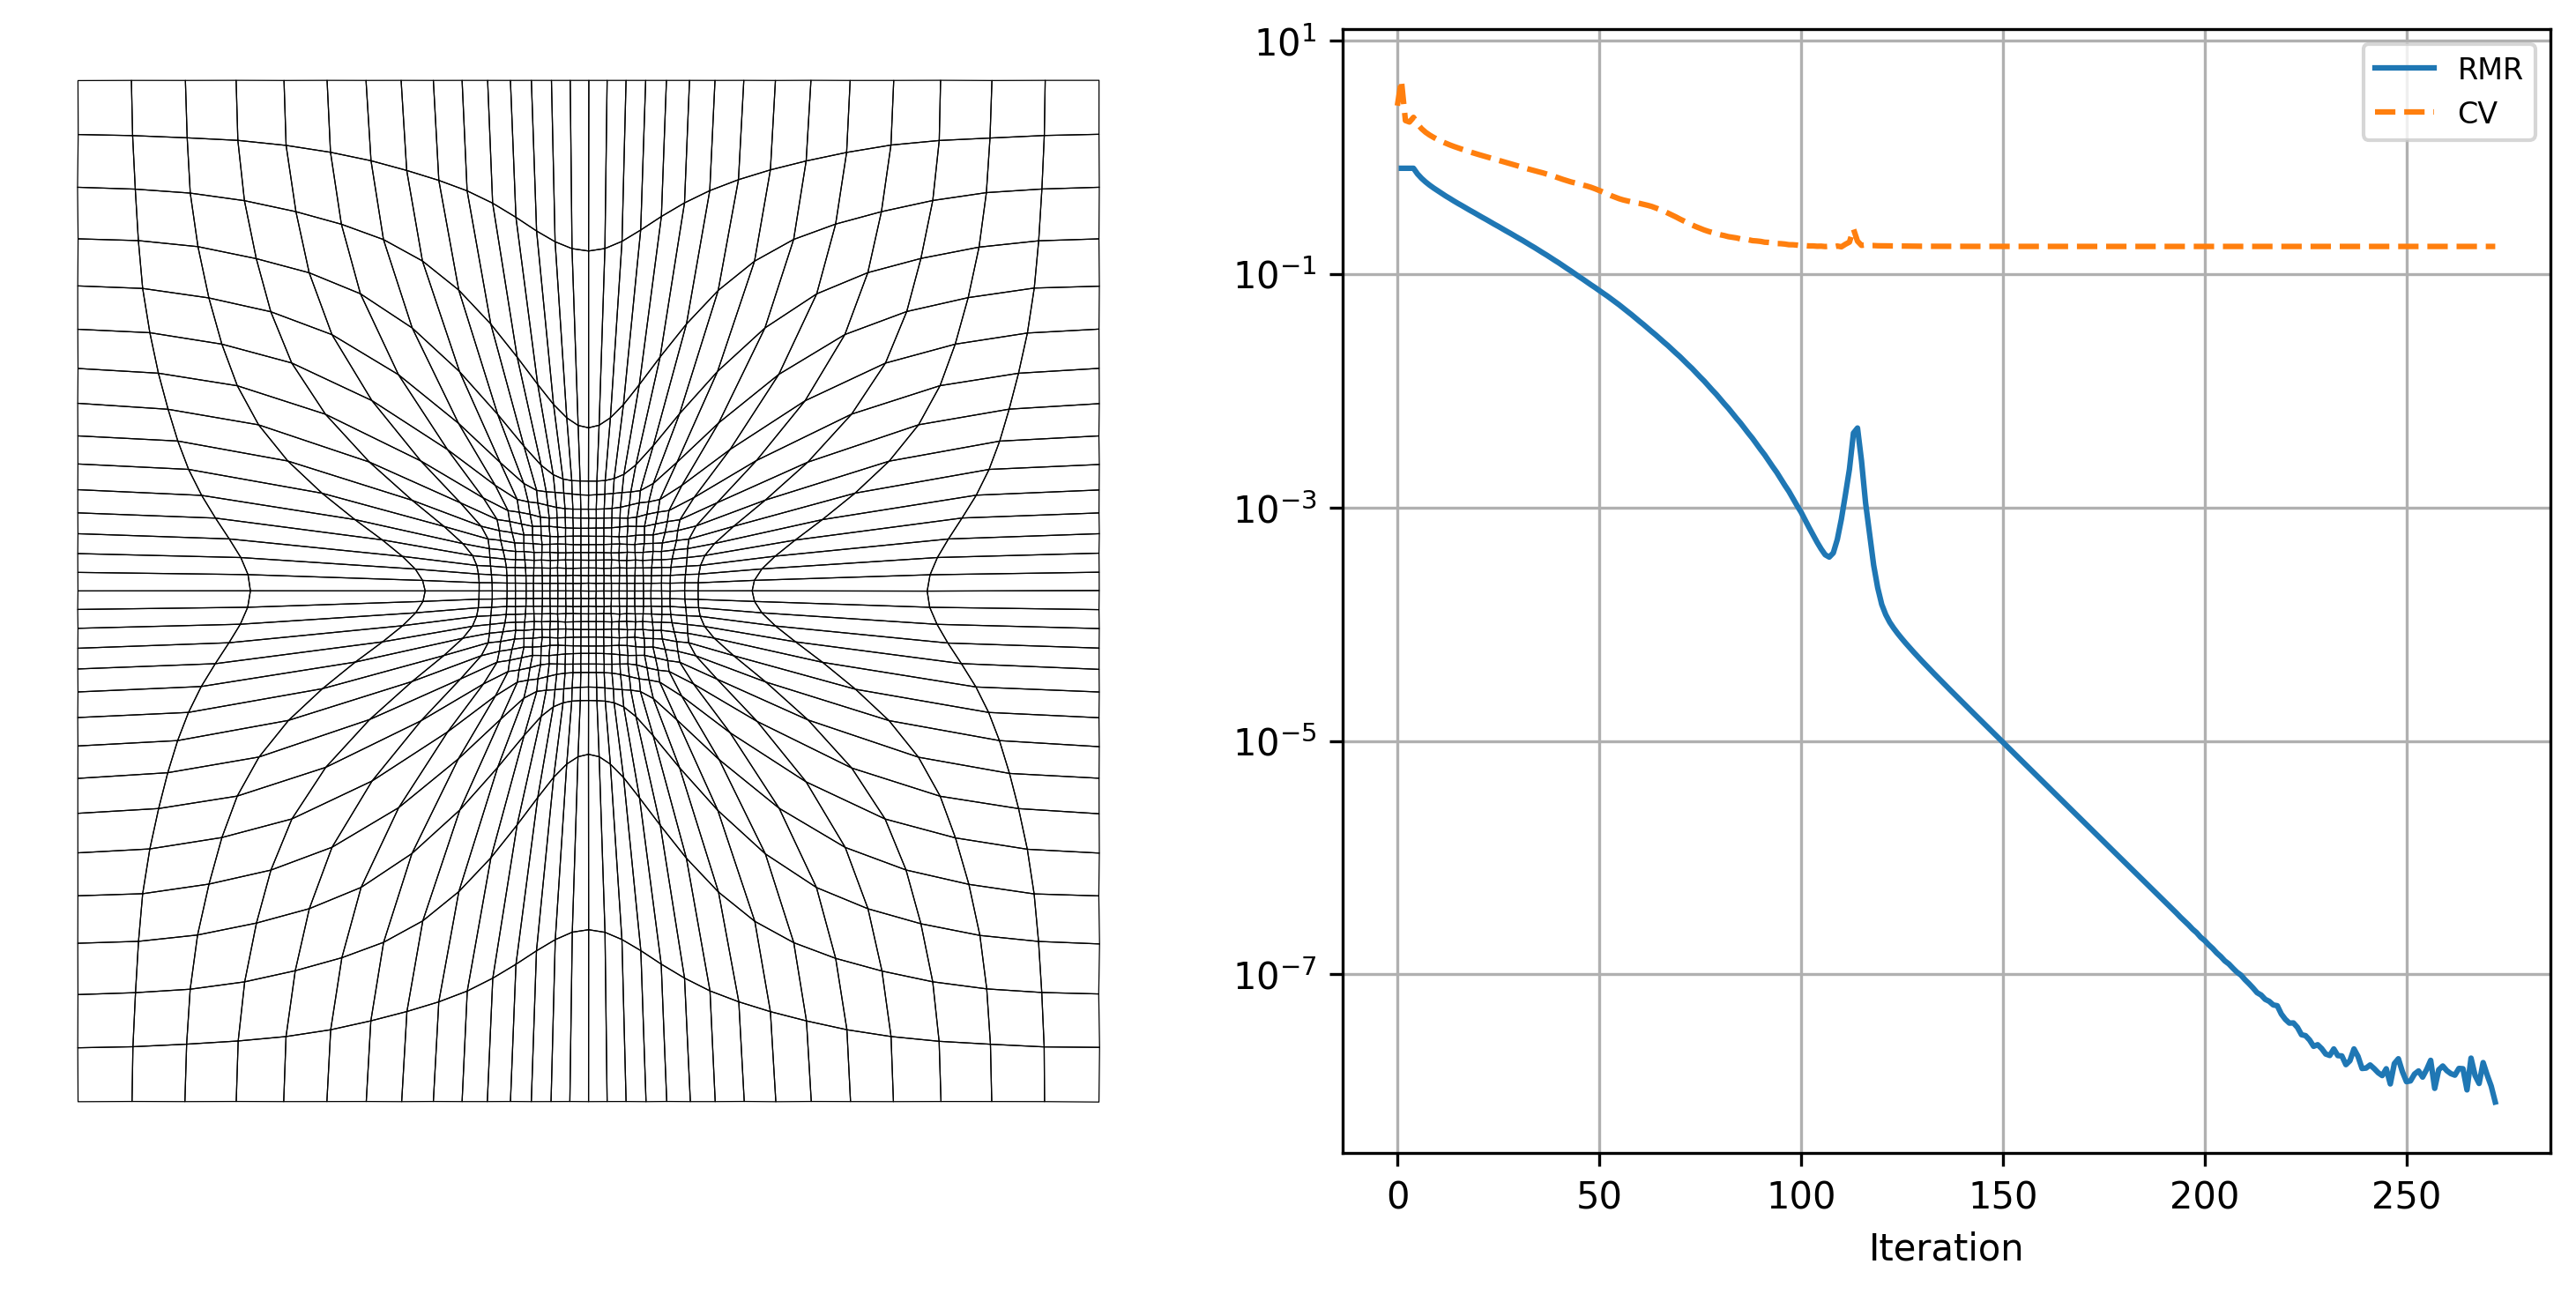

In [6]:
def monitor_bell(X):
    a = 0
    alpha1 = 50
    alpha2 = 100
    r2 = (X[:, 0] - 0.5)**2 + (X[:, 1] - 0.5)**2
    return 1.0 + alpha1 / (torch.cosh(alpha2 * (r2 - a*a)) ** 2)

domain = pyrfm.Square2D([0.5, 0.5], [0.5, 0.5])
rfm_cfg = RFMConfig(n_samples_inner=10000, n_samples_boundary=400, corner1=torch.tensor([[0.0, 0.0]], device=device), boundary_lambda=100,
                    n_hidden=1500,  gamma=2.0, n_subdomains=1, pou='PsiA', rf='tanh3', damp_value=1e-8)

it_cfg = IterationConfig(maxiter=600, rtol=1e-8, pseudo_dt=0.1, early_stop_num=20, verbose=False)

mover = RelaxationMover_RFM(domain, rfm_cfg)
mover.relaxation(monitor_bell, it_cfg)
print(f'Offline time: {mover.build_time:.2f} seconds, Online time: {mover.run_time:.2f} seconds')
print(f'CV residual: {mover.best_CV_residual:.2e}')

fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

V, T = unit_square_mesh(30, quad=True)
adapt_V = mover.move(V)
draw_quad_mesh(adapt_V, T, ax=ax[0])

ax[1].semilogy(mover.relative_move_rate_record, label="RMR")
ax[1].semilogy(mover.CV_residual_record, "--", label="CV")
ax[1].legend(fontsize=8)
ax[1].set_xlabel("Iteration")
ax[1].grid(True)

plt.tight_layout()
plt.savefig('bell.pdf', bbox_inches='tight')
plt.show()
plt.close()

del mover